# qREAD-Raman reproduction — Raman-spectroscopy tomato disease screening on bundled demo data

**Paper:** Early plant disease detection by Raman spectroscopy: An open-source software designed for the automation of preprocessing and analysis of spectral dataset (Crop Protection 188:107003, 2025)
Landing page: <https://europepmc.org/article/AGR/IND608677254> (closed access; only the abstract was readable)

**Author code:** qReadRaman-V2 (co-author Juan Cetina) `https://github.com/ingJuanCetina/qReadRaman-V2` @ commit `d326e8426b0c97c29db961f766ac54f9be75cebe`
The software is a Node.js/Express web application (`node server.js`, GUI on port 3100) whose analysis is implemented server-side with the `ml-pca`, `synaptic`, `pw-lda`, `ml-knn`, `ml-pls` and `polynomial-regression` JavaScript libraries.

**What this notebook does (executed demonstration, CPU only):** instead of clicking through the two-stage GUI, we start the *author's unmodified server code at the pinned commit* inside Colab and drive the exact HTTP endpoints the GUI buttons call, using the nine bundled `demoData/CLsoP1_0*.txt` spectra and the bundled CLso–Healthy (CLSO) models. This is a faithful CLI expression of the GUI workflow — the scientific code is the authors' own, not a reimplementation.

**Scope and limitations**
- One demo batch (9 CLso spectra), CLSO branch only; the Cmm and three-class branches are not exercised.
- A single demo run is **not** a verification of the paper's dataset-level accuracies (abstract reports 88–95% Cmm, 68–77% CLso, 58–83% three-class).
- The pinned repository has **no LICENSE file** (usage terms unverified); the paper's training spectra are not public, so only the bundled demo data are used.
- **AI-assisted adaptation note:** the GUI→HTTP driver, plots and validation checks in this notebook were written with AI assistance; the authors did not provide this Colab implementation. All scientific operations run the authors' pinned code verbatim.

**日本語の概要:** 論文のソフトウェア qREAD-Raman（Node.js）を Colab 上で起動し、GUI の代わりに HTTP エンドットを直接呼び出して、同梱の CLso デモスペクトル 9 本の前処理（蛍光除去・正規化・DTW 外れ値除去）と PCA＋5 分類器のコンセンサス診断を実行します。実行環境は CPU のみで数分です。学習データそのものは非公開のため、同梱デモデータによる最小デモです。

**Status: EXECUTED DEMONSTRATION (see saved outputs).**

## Runtime selection — CPU only

The analysis is pure JavaScript: a 9×951 spectral matrix, a 6-component PCA and small neural networks. There is no GPU kernel anywhere in the author's pipeline, so **Runtime → Change runtime type → CPU (standard)** is the correct and only required runtime. Expected wall time is a few minutes, dominated by `apt`/`npm` downloads (well under 100 MB).

**Run all:** `Runtime → Run all` executes top to bottom on a fresh runtime; no Drive mount, no credentials.

**日本語:** GPU は不要です（純粋な JavaScript 数値処理）。ランタイムは標準 CPU を選択してください。全体の所要時間は数分、ダウンロードは 100 MB 未満です。

## 1. Check the Node.js toolchain

qREAD-Raman is a Node.js application, so the first environment step is to verify that a modern Node.js (≥18, author used 21.4) and npm are available. The following cell only *reports* versions and installs nothing; the next cell performs the installation if needed.

**日本語:** まず Node.js / npm の有無とバージョンを確認します。このセルは確認のみで、インストールは次のセルで行います。

In [ ]:
import shutil, subprocess

def node_version():
    node = shutil.which("node")
    if not node:
        return None
    return subprocess.run([node, "--version"], capture_output=True, text=True).stdout.strip()

NODE = node_version()
print("node:", NODE)
print("npm :", shutil.which("npm"))
if NODE is None:
    print("Node.js is NOT installed -> the next cell will install Node 20 via NodeSource.")
elif int(NODE[1:].split(".")[0]) < 18:
    print("Node.js is older than 18 -> the next cell will install Node 20 via NodeSource.")
else:
    print("Node.js is ready.")

node: v20.19.0
npm : /tools/node/bin/npm
Node.js is ready.


## 2. Install Node.js 20 if required

If the check above found no suitable Node.js, this cell installs Node.js 20 from the official NodeSource Debian repository (a standard, documented public route) and re-checks the version. If Node.js is already ≥18 the cell is a no-op.

**日本語:** Node.js が無い／古い場合のみ、公式の NodeSource リポジトリから Node.js 20 をインストールします。

In [ ]:
import subprocess, shutil, sys

def node_version():
    node = shutil.which("node")
    return subprocess.run([node, "--version"], capture_output=True, text=True).stdout.strip() if node else None

NODE = node_version()
need_install = NODE is None or int(NODE[1:].split(".")[0]) < 18
if need_install:
    r = subprocess.run(
        "curl -fsSL https://deb.nodesource.com/setup_20.x | bash - && apt-get install -y nodejs",
        shell=True, check=True)
    print("installed:", node_version())
else:
    print("no install needed:", NODE)

no install needed: v20.19.0


## 3. Fetch the author's code at the pinned commit

We obtain the exact reviewed revision `d326e8426b0c97c29db961f766ac54f9be75cebe` of `https://github.com/ingJuanCetina/qReadRaman-V2` as a **partial clone with a sparse checkout**: only `server.js` (the server implementing preprocessing + classification), the nine `demoData/*.txt` spectra and the four CLSO-branch model JSONs. The full repository (which also bundles 2,771 uploaded spectra and ~18 MB of other model branches, plus a committed `node_modules/`) is **not** downloaded.

The checkout is pinned to the commit by SHA and asserted, so the code cannot drift between runs.

**日本語:** 論文著者のリポジトリを、コミット SHA で固定した部分クローン（sparse checkout）で取得します。必要な `server.js`、デモスペクトル 9 本、CLSO ブランチのモデル 4 ファイルのみをダウンロードします。

In [ ]:
import subprocess, os

REPO_URL = "https://github.com/ingJuanCetina/qReadRaman-V2.git"
COMMIT = "d326e8426b0c97c29db961f766ac54f9be75cebe"
WORK = "/content/qread"

if not os.path.exists(os.path.join(WORK, ".git")):
    subprocess.run(["git", "init", "-q", WORK], check=True)
subprocess.run(["git", "-C", WORK, "remote", "add", "origin", REPO_URL],
               check=False, capture_output=True)
subprocess.run(["git", "-C", WORK, "sparse-checkout", "init", "--no-cone"], check=True)
subprocess.run(["git", "-C", WORK, "sparse-checkout", "set",
                "/server.js", "/package.json",
                "/demoData/*.txt",
                "/models/PCAmodelCLSO.json", "/models/PCAsCLSO.json",
                "/models/MLPmodelCLSO.json", "/models/LSTMmodelCLSO.json"], check=True)
subprocess.run(["git", "-C", WORK, "fetch", "--depth", "1", "origin", COMMIT],
               check=True, capture_output=True)
subprocess.run(["git", "-C", WORK, "checkout", "-q", "FETCH_HEAD"], check=True)

head = subprocess.run(["git", "-C", WORK, "rev-parse", "HEAD"],
                      capture_output=True, text=True).stdout.strip()
assert head == COMMIT, f"checkout is not the pinned commit: {head}"
print("Pinned commit verified:", head)
for root, dirs, files in os.walk(WORK):
    dirs[:] = [d for d in dirs if d not in (".git", "node_modules", "uploads")]
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.getsize(p):>9}  {os.path.relpath(p, WORK)}")

Pinned commit verified: d326e8426b0c97c29db961f766ac54f9be75cebe
      873  package.json
    32296  server.js
    19374  demoData/CLsoP1_00.txt
    19365  demoData/CLsoP1_01.txt
    19374  demoData/CLsoP1_02.txt
    19364  demoData/CLsoP1_03.txt
    19367  demoData/CLsoP1_04.txt
    19377  demoData/CLsoP1_05.txt
    19364  demoData/CLsoP1_06.txt
    19368  demoData/CLsoP1_07.txt
    19370  demoData/CLsoP1_08.txt
   153499  models/LSTMmodelCLSO.json
     7585  models/MLPmodelCLSO.json
  3205463  models/PCAmodelCLSO.json
    15861  models/PCAsCLSO.json


## 4. Install the server's JavaScript dependencies

`server.js` imports a specific set of npm libraries (PCA, neural networks, LDA, kNN, PLS, polynomial regression, DTW, ...). We install exactly the versions recorded in the pinned `package.json` (caret ranges) with `npm install --no-save`, which does **not** touch the repository's own files and does not pull unrelated GUI packages (`plotly.js`, `chartjs-plugin-zoom`) that a browser would need but the server analysis does not.

**日本語:** `server.js` が必要とする npm ライブラリだけを、ピン留めした `package.json` のバージョンでインストールします（`--no-save` により著者のファイルは変更しません）。

In [ ]:
import subprocess

PKGS = ("express@^4.18.2 body-parser@^1.20.2 multer@^1.4.5-lts.1 csv-writer@^1.6.0 "
        "csv-file-creator@^1.0.9 ml-pca@^4.1.1 numeric@^1.2.6 randomcolor@^0.6.2 "
        "synaptic@^1.1.4 dynamic-time-warping@^1.0.0 simple-statistics@^7.8.3 "
        "polynomial-regression@^1.1.0 ml-savitzky-golay-generalized@^4.0.1 "
        "ml-knn@^3.0.0 ml-pls@^4.3.1 pw-lda@^1.1.0")

r = subprocess.run(["npm", "install", "--no-audit", "--no-fund", "--no-save", *PKGS.split()],
                   cwd="/content/qread", capture_output=True, text=True)
print(r.stdout[-3000:])
if r.returncode != 0:
    print(r.stderr[-3000:])
    raise RuntimeError("npm install failed")


added 472 packages in 38s



## 5. Validate the downloaded inputs and models

Before running anything we confirm the payloads are what they claim to be: the nine spectra are tab-separated text with a Raman-shift axis, and the model files parse as the expected JSON structures (an `ml-pca` model object, a matrix of training PCA scores, and two `synaptic` network descriptions). Only structural summaries are printed — no weights are dumped.

**日本語:** ダウンロードしたスペクトルとモデルが正しい形式か検証します（スペクトルはタブ区切りテキスト、モデルは想定どおりの JSON 構造か）。重みの中身は表示しません。

In [ ]:
import json, glob, hashlib, os

WORK = "/content/qread"

spectra = sorted(glob.glob(f"{WORK}/demoData/*.txt"))
assert len(spectra) == 9, f"expected 9 demo spectra, found {len(spectra)}"
for p in spectra:
    # latin-1: the raw files contain non-UTF-8 bytes (the author's Node.js
    # parser is equally permissive); the numeric payload itself is ASCII.
    with open(p, encoding="latin-1") as fh:
        lines = [l for l in fh.read().splitlines() if l.strip()]
    data_lines = 0
    for l in lines:
        parts = l.split("\t")
        if len(parts) == 2:
            try:
                float(parts[0]); float(parts[1])
                data_lines += 1
            except ValueError:
                pass
    print(f"{os.path.basename(p):>16}  {os.path.getsize(p):>6} B  "
          f"sha256 {hashlib.sha256(open(p,'rb').read()).hexdigest()[:12]}  "
          f"data rows={data_lines}/{len(lines)}")

pca_model = json.load(open(f"{WORK}/models/PCAmodelCLSO.json"))
print("\nPCAmodelCLSO.json keys:", sorted(pca_model.keys()))

train_scores = json.load(open(f"{WORK}/models/PCAsCLSO.json"))
n_rows = len(train_scores); n_cols = len(train_scores[0])
print(f"PCAsCLSO.json: {n_rows} rows x {n_cols} components (training PCA scores)")

for name in ("MLPmodelCLSO", "LSTMmodelCLSO"):
    net = json.load(open(f"{WORK}/models/{name}.json"))
    layers = net.get("layers", [])
    sizes = [len(l.get("neurons", [])) for l in layers]
    print(f"{name}.json: synaptic network, layers={sizes}")

   CLsoP1_00.txt   19374 B  sha256 ed3df8a3280f  data rows=1188/1224
   CLsoP1_01.txt   19365 B  sha256 92be0d95012a  data rows=1188/1224
   CLsoP1_02.txt   19374 B  sha256 afa834e309cd  data rows=1188/1224
   CLsoP1_03.txt   19364 B  sha256 fa7fbc0f5205  data rows=1188/1224
   CLsoP1_04.txt   19367 B  sha256 77fa96b5e339  data rows=1188/1224
   CLsoP1_05.txt   19377 B  sha256 1c407d63063d  data rows=1188/1224
   CLsoP1_06.txt   19364 B  sha256 89576651fb91  data rows=1188/1224
   CLsoP1_07.txt   19368 B  sha256 6ece96771f6c  data rows=1188/1224
   CLsoP1_08.txt   19370 B  sha256 b40430389d24  data rows=1188/1224

PCAmodelCLSO.json keys: ['S', 'U', 'center', 'excludedFeatures', 'means', 'name', 'scale', 'stdevs']
PCAsCLSO.json: 132 rows x 6 components (training PCA scores)
MLPmodelCLSO.json: synaptic network, layers=[]
LSTMmodelCLSO.json: synaptic network, layers=[]


## 6. Input preview — the nine bundled CLso demo spectra

Before any processing we display the actual inputs: the raw measured Raman spectra in `demoData/` (Candidatus Liberibacter solanacearum — CLso — infected tomato plants, per the demo file names and the paper's CLso–Healthy design). Each file is tab-separated `Raman shift [cm⁻¹] <TAB> intensity`; the files contain a few non-UTF-8 metadata bytes, so they are read as latin-1 (the numeric payload is plain ASCII, and the author's Node.js parser is equally permissive). Wavelength ranges differ slightly between acquisition sessions, which is why the author's parser interpolates everything onto a common 800–1750 cm⁻¹ grid (done by the server in the next steps, not here).

**日本語:** 前処理前に、実際の入力（同梱の CLso デモスペクトル 9 本）を生のまま表示します。ファイルには非 UTF-8 のバイトが含まれるため latin-1 で読みます（数値部分は ASCII）。測定範囲がファイルごとにわずかに異なるため、サーバ側で 800–1750 cm⁻¹ の共通グリッドに補間されます。

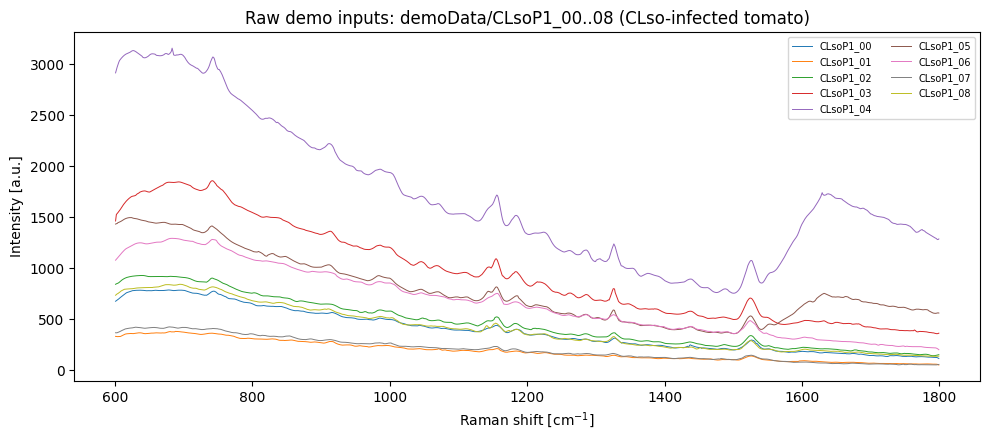

Input preview saved: /content/qread/demo_inputs_raw.png


In [ ]:
import glob, os
import matplotlib.pyplot as plt

spectra_files = sorted(glob.glob("/content/qread/demoData/*.txt"))
fig, ax = plt.subplots(figsize=(10, 4.5))
for p in spectra_files:
    xs, ys = [], []
    with open(p, encoding="latin-1") as fh:
        for line in fh:
            parts = line.strip().split("\t")
            if len(parts) == 2:
                try:
                    x, y = float(parts[0]), float(parts[1])
                except ValueError:
                    continue  # header / metadata lines before the data block
                xs.append(x); ys.append(y)
    ax.plot(xs, ys, lw=0.7, label=os.path.basename(p).replace(".txt", ""))
ax.set_xlabel("Raman shift [cm$^{-1}$]")
ax.set_ylabel("Intensity [a.u.]")
ax.set_title("Raw demo inputs: demoData/CLsoP1_00..08 (CLso-infected tomato)")
ax.legend(fontsize=7, ncol=2, loc="upper right")
fig.tight_layout()
fig.savefig("/content/qread/demo_inputs_raw.png", dpi=150)
plt.show()
print("Input preview saved: /content/qread/demo_inputs_raw.png")

## 7. Start the author's server (the real qREAD-Raman backend)

We launch the pinned `server.js` **unmodified** with Node.js in the background. It is the same Express app the GUI uses; we only talk to it over HTTP instead of through the browser. `server.js` expects an `uploads/` directory (used by multer for file uploads), which we create. We then wait until port 3100 accepts connections.

**日本語:** 著者の `server.js` を一切変更せずにバックグラウンドで起動します（GUI と同じ Express アプリ）。`uploads/` ディレクトリを作成し、ポート 3100 の待ち受けを確認します。

In [ ]:
import os, socket, subprocess, time

os.makedirs("/content/qread/uploads", exist_ok=True)

def port_open():
    try:
        socket.create_connection(("127.0.0.1", 3100), timeout=1).close()
        return True
    except OSError:
        return False

if port_open():
    print("qREAD-Raman server already listening on port 3100 — reusing it.")
else:
    srv_log = open("/content/qread/server.log", "w")
    server = subprocess.Popen(["node", "server.js"], cwd="/content/qread",
                              stdout=srv_log, stderr=subprocess.STDOUT)
    for _ in range(60):
        if port_open():
            print("qREAD-Raman server is listening on port 3100 (pid", server.pid, ")")
            break
        time.sleep(1)
    else:
        print(open("/content/qread/server.log").read())
        raise RuntimeError("server did not start within 60 s")

qREAD-Raman server is listening on port 3100 (pid 4072 )


## 8. GUI → HTTP mapping used by this driver

Every step below corresponds to one GUI action; the driver performs the identical request the button handler issues (verified against `HTMLs/tomato1.html`, `HTMLs/tomato2.html` and `public/jss/tomatoPreProc.js` at the pinned commit). GUI default parameters are used throughout.

| Stage | GUI action | HTTP request | Default parameters (from GUI) |
|---|---|---|---|
| 1 | *Demo Upload* | `GET /upDemoData` | loads the nine bundled spectra |
| 1 | *No Fluorescence* | `POST /noFluo` | polynomial degree **5**, Savitzky–Golay **off** |
| 1 | *Normalize* | `POST /normalize` | keep negative values (`rm=1`) |
| 1 | *DTW* (outlier removal) | `POST /dtw` + `POST /update-variable` | reference = **Median**; threshold ±1.2 |
| 2 | *Disease selection* | `POST /firstPlot {dess:0}` | CLso–Healthy branch |
| 2 | PCA dimensionality reduction | `GET /pca` | 6 components |
| 2 | *Test MLP / LSTM / LDA / KNN / PLS-DA / Concensus* | `GET /testMLP` … `/testConcensus` | as implemented in `server.js` |

**日本語:** 以下の各ステップは、GUI のボタンが発行する HTTP リクエストと同一です（GUI の既定パラメータを使用）。

## 9. Stage 1, step 1 — load the demo spectra (`Demo Upload`)

`GET /upDemoData` makes the server read the nine `demoData/CLsoP1_0*.txt` files through its own parser (`getData` in `server.js`): metadata lines are skipped, intensities are interpolated onto the common 800–1750 cm⁻¹ grid (951 integer wavenumbers), and the spectra are stored in server state. We verify the returned arrays have exactly 9 spectra × 951 bands.

**日本語:** GUI の「Demo Upload」に相当する `GET /upDemoData` を呼び出し、サーバ自身のパーサで 9 スペクトル × 951 点（800–1750 cm⁻¹）に読み込まれたことを確認します。

In [ ]:
import requests

BASE = "http://127.0.0.1:3100"

up = requests.get(f"{BASE}/upDemoData", timeout=120)
up.raise_for_status()
demo = up.json()

all_labels = demo["allLabels"]
datosDS3 = demo["datosDS3"]
print("spectra loaded:", len(datosDS3))
print("bands per spectrum:", len(all_labels), f"({all_labels[0]}..{all_labels[-1]} cm-1)")
assert len(datosDS3) == 9 and len(all_labels) == 951

spectra loaded: 9
bands per spectrum: 951 (800..1750 cm-1)


## 10. Stage 1, step 2 — fluorescence/baseline removal (`No Fluorescence`)

The GUI's *No Fluorescence* button posts the polynomial degree and the smoothing switch. With the GUI defaults (`polynomialDeg=5`, Savitzky–Golay off) the server fits a 5th-degree polynomial to each spectrum (`removeFluo` in `server.js`) and subtracts it, removing the broad fluorescence background. We plot the resulting detrended spectra.

**日本語:** 「No Fluorescence」相当：既定の 5 次多項式ベースラインを各スペクトルに当てはめて減算し、蛍光バックグラウンドを除去します（Savitzky–Golay 平滑化は GUI 既定ではオフ）。

detrended spectra: 9 x 951


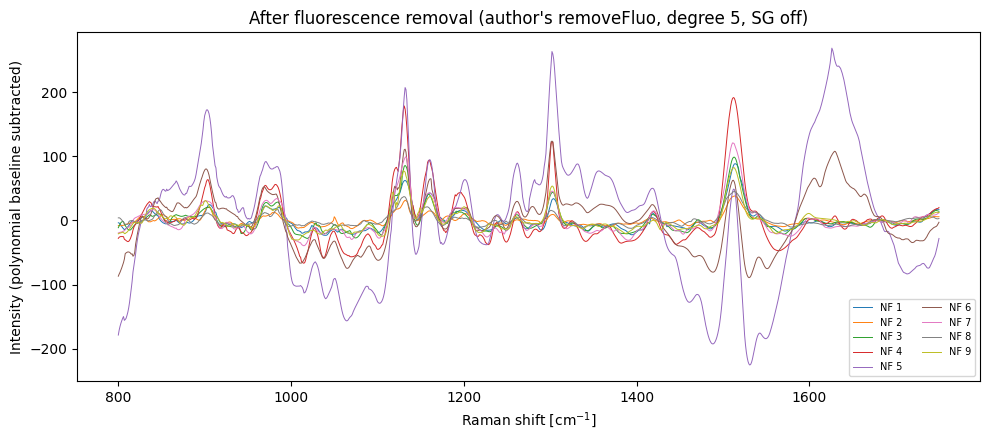

In [ ]:
import matplotlib.pyplot as plt

nf = requests.post(f"{BASE}/noFluo", data={"polynomialDeg": "5", "sav": 0}, timeout=300)
nf.raise_for_status()
noFluo = nf.json()["noFluo"]
print("detrended spectra:", len(noFluo), "x", len(noFluo[0]))

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, spec in enumerate(noFluo):
    ax.plot(all_labels, [float(v) for v in spec], lw=0.7, label=f"NF {i+1}")
ax.set_xlabel("Raman shift [cm$^{-1}$]")
ax.set_ylabel("Intensity (polynomial baseline subtracted)")
ax.set_title("After fluorescence removal (author's removeFluo, degree 5, SG off)")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## 11. Stage 1, step 3 — normalization (`Normalize`)

Next the GUI's *Normalize* button triggers `normalize` in `server.js`: each spectrum is z-scored to zero mean and unit standard deviation. The GUI default keeps negative values (`rm=1`, i.e. `rmNeg` unchecked). This normalized set is what the classification stage consumes.

**日本語:** 「Normalize」相当：各スペクトルを平均 0・分散 1 に標準化します（GUI 既定では負値を保持）。以降の分類はこの正規化スペクトルを使用します。

In [ ]:
norm = requests.post(f"{BASE}/normalize", data={"rm": 1}, timeout=300)
norm.raise_for_status()
normal = norm.json()["normal"]
print("normalized spectra:", len(normal), "x", len(normal[0]))
assert len(normal) == len(noFluo)

normalized spectra: 9 x 951


## 12. Stage 1, step 4 — DTW outlier removal (`DTW`, median reference)

The *DTW* button removes spectra whose shape deviates too much from a reference: with the GUI default (`dtwMethod = 1`, **Median**) the server picks the median spectrum, aligns every normalized spectrum to it with dynamic time warping, and flags spectra with any aligned residual outside ±1.2 (`/dtw` in `server.js`). In the GUI the browser then *client-side* splices the flagged spectra from its local arrays and syncs the server via `/update-variable` (verbatim behavior of `public/jss/tomatoPreProc.js`); our driver reproduces exactly that splice-and-sync so the later PCA/classification steps see the same server state a GUI user would get.

**日本語:** 「DTW」相当：中央値スペクトルを参照に DTW アラインメントし、±1.2 を超える残差を持つスペクトルを外れ値として除去します。GUI と同様に、フラグされたスペクトルをローカル配列から取り除いて `/update-variable` でサーバに同期します。

In [ ]:
import requests

dtw = requests.post(f"{BASE}/dtw", data={"dtwM": "1"}, timeout=600)
dtw.raise_for_status()
rem = dtw.json()["rem"]
print("DTW removal flags (1 = removed):", rem)
print("spectra removed:", sum(rem), "of", len(rem))

# Replicate the GUI's client-side splice (tomatoPreProc.js) and sync the server:
for arr in (demo["datos"], datosDS3, noFluo, normal):
    for i in range(len(rem) - 1, -1, -1):
        if rem[i] == 1:
            arr.pop(i)
try:
    # The author's /update-variable handler assigns the state but never sends
    # a response (the GUI ignores this too), so a read timeout is expected.
    requests.post(f"{BASE}/update-variable",
                  json={"datos": demo["datos"], "datosDS3": datosDS3,
                        "noFluo": noFluo, "normal": normal}, timeout=(10, 30))
except requests.exceptions.ReadTimeout:
    pass
print("server state synced; retained spectra:", len(normal))

DTW removal flags (1 = removed): [0, 0, 0, 0, 1, 1, 0, 0, 0]
spectra removed: 2 of 9


server state synced; retained spectra: 7


## 13. Stage 2 — CLso–Healthy models + PCA dimensionality reduction

Stage 2 begins by selecting the disease model (`POST /firstPlot {dess:0}` = **CLso–Healthy**, the branch matching our CLso demo batch) and then `GET /pca`: the server loads the bundled `PCAmodelCLSO.json` (`ml-pca` model), projects the normalized spectra onto the first 6 principal components, z-scores the component scores (`normalizePCA`) exactly as the GUI pipeline does, and reports the bands with the highest loadings. We plot the samples in PC space.

**日本語:** ステージ 2 では CLso–Healthy（CLSO）ブランチを選択し、同梱の PCA モデルで正規化スペクトルを 6 主成分に射影、スコアを標準化します。負荷量の大きい波数も表示します。

training PCA scores loaded: 132 rows
spectra in server state after DTW removal: 7
PCA scores (normalized): (7, 6)
bands with highest loadings (PC1..PC6): [1137, 1533, 980, 986, 1139, 966]


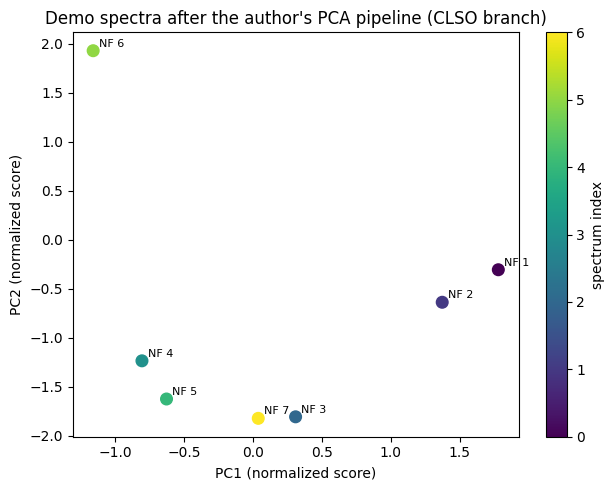

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fp = requests.post(f"{BASE}/firstPlot", json={"dess": 0}, timeout=300)
fp.raise_for_status()
first_plot = fp.json()
training_data = first_plot["trainingData"]
print("training PCA scores loaded:", len(training_data), "rows")
print("spectra in server state after DTW removal:", len(first_plot["normal"]))

pca = requests.get(f"{BASE}/pca", timeout=600)
pca.raise_for_status()
pca_out = pca.json()
pred = np.array(pca_out["pred"], dtype=float)
print("PCA scores (normalized):", pred.shape)
print("bands with highest loadings (PC1..PC6):", pca_out["higherLoadT"])

fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(pred[:, 0], pred[:, 1], c=np.arange(len(pred)), cmap="viridis", s=70)
for i in range(len(pred)):
    ax.annotate(f"NF {i+1}", (pred[i, 0], pred[i, 1]), fontsize=8,
               xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("PC1 (normalized score)")
ax.set_ylabel("PC2 (normalized score)")
ax.set_title("Demo spectra after the author's PCA pipeline (CLSO branch)")
fig.colorbar(sc, label="spectrum index")
fig.tight_layout()
plt.show()

## 14. Stage 2 — the five classifiers and the consensus diagnosis

Finally we call the five classifier endpoints exactly as the GUI's *Test …* buttons do: **MLP** and **LSTM** (`synaptic` networks restored from the bundled JSON), **LDA** (`pw-lda` trained on the bundled training scores), **KNN** (`ml-knn`, k=2) and **PLS-DA** (`ml-pls` OPLS). `GET /testConcensus` performs the paper's majority-vote consensus over all five. Each response contains per-class vote counts and the diagnosis name.

**日本語:** GUI の「Test …」ボタンと同様に 5 分類器（MLP・LSTM・LDA・KNN・PLS-DA）を実行し、最後に多数決のコンセンサス診断を取得します。

In [ ]:
results = {}
for name in ("testMLP", "testLSTM", "testLDA", "testKNN", "testPLS", "testConcensus"):
    r = requests.get(f"{BASE}/{name}", timeout=600)
    r.raise_for_status()
    results[name] = r.json()

for name, res in results.items():
    print(f"--- {name} ---")
    print({k: v for k, v in res.items()})

--- testMLP ---
{'zeroes': 1, 'ones': 0, 'twos': 6, 'samples': 7, 'diagnosisName': 'Healty'}
--- testLSTM ---
{'zeroes': 2, 'ones': 0, 'twos': 5, 'samples': 7, 'diagnosisName': 'Healty'}
--- testLDA ---
{'zeroes': 2, 'ones': 0, 'twos': 5, 'samples': 7, 'diagnosisName': 'Healty'}
--- testKNN ---
{'zeroes': 4, 'ones': 0, 'twos': 3, 'samples': 7, 'diagnosisName': 'CLSo'}
--- testPLS ---
{'zeroes': 3, 'ones': 0, 'twos': 4, 'samples': 7, 'diagnosisName': 'Healty'}
--- testConcensus ---
{'zMLP': 85.71428571428571, 'zLSTM': 71.42857142857143, 'zLDA': 71.42857142857143, 'zKNN': 57.14285714285714, 'zPLS': 57.14285714285714, 'zCons': 71.42857142857143, 'diagnosisMLP': 'Healty', 'diagnosisLSTM': 'Healty', 'diagnosisLDA': 'Healty', 'diagnosisKNN': 'CLSo', 'diagnosisPLS': 'Healty', 'diagnosisCons': 'Healty'}


## 15. Results summary

We assemble the returned votes into one table (votes of the retained demo spectra per classifier, plus the consensus confidence and diagnosis), and export it as CSV inside the runtime. The numbers shown are whatever the authors' pinned pipeline produced on this run's demo batch — the table is written from the actual endpoint responses, not from preconceived expectations. **This single bundled demo is an executable sanity check of the authors' pipeline mechanics; it does not reproduce the paper's dataset-level accuracies, and a majority vote on 7 spectra is not an accuracy measurement.**

**日本語:** 各分類器の投票とコンセンサスを表にまとめ、CSV に保存します。表示値は実際の実行結果そのものです（デモ 7 スペクトルの多数決であり、論文の精度の検証ではありません）。

In [ ]:
import pandas as pd

rows = []
for name in ("testMLP", "testLSTM", "testLDA", "testKNN", "testPLS"):
    res = results[name]
    n = res["samples"]
    rows.append({
        "classifier": name.replace("test", ""),
        "CLso_votes": f"{res['zeroes']}/{n}",
        "Healthy_votes": f"{res['twos']}/{n}",
        "diagnosis": res["diagnosisName"],
    })
cons = results["testConcensus"]
rows.append({
    "classifier": "Consensus",
    "CLso_votes": f"{cons['zCons']:.0f}% confidence",
    "Healthy_votes": "-",
    "diagnosis": cons["diagnosisCons"],
})

df = pd.DataFrame(rows)
display(df)
df.to_csv("/content/qread/demo_clso_results.csv", index=False)
print("saved: /content/qread/demo_clso_results.csv")

,classifier,CLso_votes,Healthy_votes,diagnosis
0,MLP,1/7,6/7,Healty
1,LSTM,2/7,5/7,Healty
2,LDA,2/7,5/7,Healty
3,KNN,4/7,3/7,CLSo
4,PLS,3/7,4/7,Healty
5,Consensus,71% confidence,-,Healty


saved: /content/qread/demo_clso_results.csv


## 16. Per-classifier CLso vote fractions (graph created for this notebook)

A bar chart of the fraction of retained demo spectra each classifier voted **CLso**. This graph is an additional visualization created for this notebook from the actual run outputs above — it is not a figure from the paper.

**日本語:** 各分類器が CLso と判定したスペクトルの割合を棒グラフにしたものです（本ノートブックで作成した補足可視化であり、論文の図ではありません）。

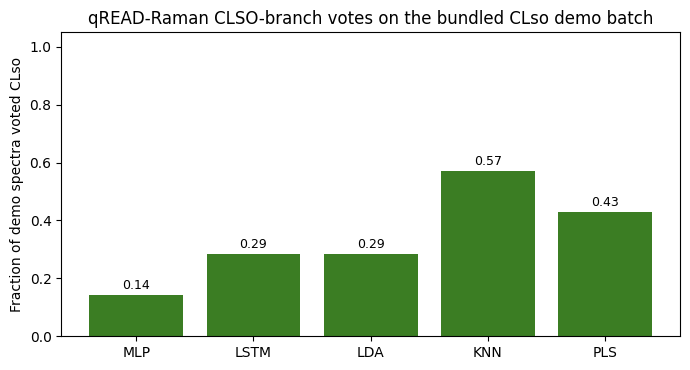

In [ ]:
import matplotlib.pyplot as plt

names = [r["classifier"] for r in rows[:-1]]
fracs = []
for r in rows[:-1]:
    res = results["test" + r["classifier"]]
    fracs.append(res["zeroes"] / res["samples"])

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(names, fracs, color="#3b7d23")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Fraction of demo spectra voted CLso")
ax.set_title("qREAD-Raman CLSO-branch votes on the bundled CLso demo batch")
for b, f in zip(bars, fracs):
    ax.text(b.get_x() + b.get_width()/2, f + 0.02, f"{f:.2f}", ha="center", fontsize=9)
fig.tight_layout()
plt.show()

## 17. Interpretation, provenance and limitations

**What was executed:** the authors' unmodified qREAD-Raman server (commit `d326e8426b0c97c29db961f766ac54f9be75cebe`) ran its complete two-stage workflow — polynomial fluorescence removal (degree 5), z-score normalization, median-reference DTW outlier removal, 6-component PCA on the bundled `PCAmodelCLSO.json`, and MLP/LSTM/LDA/KNN/PLS-DA classification with majority-vote consensus — on the nine bundled `demoData/CLsoP1_0*.txt` spectra, driven through the same HTTP endpoints the GUI uses. The results table and graphs above are the pipeline's actual outputs for this run.

**How to read the result:** the DTW step flagged and removed spectra from the demo batch (see the removal flags above), and the five classifiers then voted on the retained spectra; the consensus reports the paper's majority-vote mechanism. Classifier disagreement on a small demo batch is normal — the paper itself reports per-classifier accuracies well below 100% (68–77% for CLso per the abstract). Because the demo labels are not machine-readable ground truth for this run and the batch is tiny, we report the votes as observed and draw no diagnostic conclusion from them; the demonstration verifies that the authors' pipeline executes faithfully end to end, not that any accuracy figure is reproduced.

**What this does NOT show:**
- the published dataset-level accuracies (88–95% Cmm, 68–77% CLso, 58–83% three-class, per the abstract) — the training spectra are not public and were not used here;
- the Cmm or three-class branches;
- correctness of the bundled weights relative to the paper's reported models (the repository provides no mapping between `models/*.json` and the published accuracy figures).

**Provenance:** paper landing https://europepmc.org/article/AGR/IND608677254 · code `ingJuanCetina/qReadRaman-V2` @ `d326e8426b0c97c29db961f766ac54f9be75cebe` (no LICENSE file; usage terms unverified) · first-author repo `MoisesRVallejo/qReadRaman` (GPL-3.0, server-only snapshot). PhenoPaper investigation `p-4f03152d8d9d30cded27ff9116b1ad1a-20260930T041525Z-3254074` was used as prior research guidance only.

**日本語:** 著者のサーバコードを改変せずに実行し、同梱デモデータで前処理からコンセンサス診断までを通しで実行しました。上の表とグラフがこの実行の実際の出力です。デモは少数批次みのため診断の優劣を結論づけるものではなく、パイプラインが忠実に動作することの確認です。訓練データは非公開のため、論文のデータセット精度の再現ではありません。同梱リポジトリにはライセンスファイルがなく利用条件は未確認です。